# fMRI preprocessing

In [1]:
import sys
import os

#####################
# Import of utils.py functions
#####################
notebook_dir = os.path.abspath("data/Desktop/myfiles/NSSP/Mini Project 1")      # = .../NSSP/Mini Project 1
parent_dir = os.path.abspath(os.path.join(notebook_dir, 'data/Desktop/myfiles/NSSP'))  # = .../NSSP
sys.path.append(parent_dir)
sys.path.append('.')
from utils import loadFSL, FSLeyesServer, mkdir_no_exist

####################
# DIPY_HOME (avant tout import de dipy)
####################
os.environ["DIPY_HOME"] = "/home/jovyan/Data"

#############################
# Loading FSL and FreeSurfer within Neurodesk
#############################
import module as lmod
await lmod.purge(force=True)
await lmod.load('fsl/6.0.7.18')
await lmod.load('freesurfer/7.4.1')
await lmod.list()

####################
# Setup FSL path
####################
loadFSL()

###################
# Libraries
###################
import glob
import json
import numpy as np
import pandas as pd
import nibabel as nib
import nilearn
import subprocess
import fsl.wrappers
import matplotlib.pyplot as plt
import os.path as op
from nilearn import plotting, image
from fsl.wrappers import mcflirt, fslmaths, fast, bet, flirt, epi_reg
from fsl.wrappers.misc import fslroi

###################
# Paths du Mini Project 1
###################
project_dir = op.abspath("")   # dossier du notebook : "Mini Project 1"
nii_file = op.join(project_dir, "tfMRI_LANGUAGE_LR.nii")   # <-- à remplacer
csv_file = op.join(project_dir, "tfMRI_LANGUAGE_LR_task_onsets.csv")      # <-- à remplacer

# Dossier de sortie pour les résultats du preprocessing
output_dir = op.join(project_dir, "derivatives")
mkdir_no_exist(output_dir)

# Vérification que les fichiers existent
#print("NIfTI :", nii_file, "->", os.path.exists(nii_file))
#print("CSV   :", csv_file, "->", os.path.exists(csv_file))

###################
# Chargement des données
###################
img = nib.load(nii_file)
#print("Shape :", img.shape)            # 4D = (x, y, z, volumes)
#print("Voxel size / TR :", img.header.get_zooms())

#task_df = pd.read_csv(csv_file)
#task_df.head()

In [3]:
%gui wx

In [4]:
################
# Start FSLeyes (very neat tool to visualize MRI data of all sorts) within Python
################
fsleyesDisplay = FSLeyesServer()
fsleyesDisplay.show()
fsleyesDisplay.load(nii_file)

10:03:47: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:03:47: Debug: Adding duplicate animation handler for '1' type
10:03:47: Debug: Adding duplicate animation handler for '2' type
10:03:47: Debug: Adding duplicate image handler for 'Windows bitmap file'
10:03:47: Debug: Adding duplicate animation handler for '1' type
10:03:47: Debug: Adding duplicate animation handler for '2' type

(ipykernel_launcher.py:784): Gtk-CRITICAL **: 10:03:48.080: gtk_window_resize: assertion 'width > 0' failed

(ipykernel_launcher.py:784): Gtk-CRITICAL **: 10:04:07.745: gtk_window_resize: assertion 'width > 0' failed


# Field Stabilization

Text(0, 0.5, 'Mean voxel intensity')

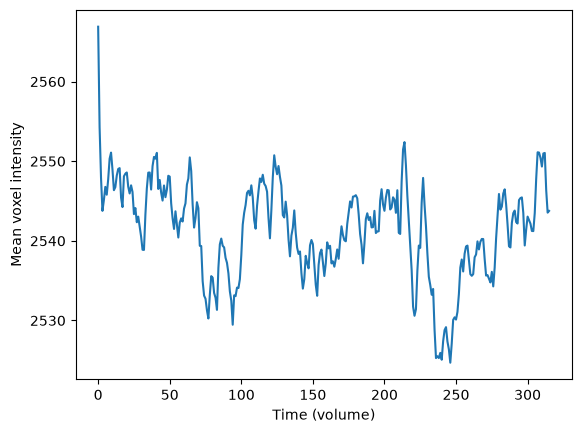

In [5]:
plt.plot(nib.load(op.join(project_dir, 'tfMRI_LANGUAGE_LR.nii')).get_fdata().mean(axis=(0,1,2)))
plt.xlabel('Time (volume)')
plt.ylabel('Mean voxel intensity')

Est ce que ça vaut le coup d'enlever 5 volume sur 320 ?

# Motion Correction

In [6]:
preproc_root = op.join(project_dir, 'derivatives', 'preprocessed_data')
mkdir_no_exist(op.join(project_dir, 'derivatives'))
mkdir_no_exist(preproc_root)

# Entrée / sortie (sans extension, FSL la gère)
path_original_data = op.join(project_dir, 'tfMRI_LANGUAGE_LR')
path_moco_data = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco')

mcflirt(infile=path_original_data, o=path_moco_data,
        plots=True, report=True, dof=6, mats=True)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(path_original_data)
fsleyesDisplay.load(path_moco_data)

Processed data will be saved as /data/Desktop/myfiles/NSSP/Mini Project 1/derivatives/preprocessed_data/tfMRI_LANGUAGE_LR_moco

McFLIRT v 2.0 - FMRI motion correction

Reading time series... 
first iteration - 8mm scaling, set tolerance
Rescaling reference volume [158] to 8 mm pixels
Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][

refnum = 158
Original_refvol = -1


Registering volumes ... [159][160][161][162][163][164][165][166][167][168][169][170][171][172][173][174][175][176][177][178][179][180][181][182][183][184][185][186][187][188][189][190][191][192][193][194][195][196][197][198][199][200][201][202][203][204][205][206][207][208][209][210][211][212][213][214][215][216][217][218][219][220][221][222][223][224][225][226][227][228][229][230][231][232][233][234][235][236][237][238][239][240][241][242][243][244][245][246][247][248][249][250][251][252][253][254][255][256][257][258][259][260][261][262][263][264][265][266][267][268][269][270][271][272][273][274][275][276][277][278][279][280][281][282][283][284][285][286][287][288][289][290][291][292][293][294][295][296][297][298][299][300][301][302][303][304][305][306][307][308][309][310][311][312][313][314][315][157][156][155][154][153][152][151][150][149][148][147][146][145][144][143][142][141][140][139][138][137][136][135][134][133][132][131][130][129][128][127][126][125][124][123][122][121][120][

# Framewise Displacement

In [7]:
def load_mot_params_fsl_6_dof(path):
    return pd.read_csv(path, sep='  ', header=None, 
            engine='python', names=['Rotation x', 'Rotation y', 'Rotation z','Translation x', 'Translation y', 'Translation z'])

mot_params = load_mot_params_fsl_6_dof(op.join(preproc_root,'tfMRI_LANGUAGE_LR_moco.par'))

In [8]:
def compute_FD_power(mot_params):
    framewise_diff = mot_params.diff().iloc[1:]

    rot_params = framewise_diff[['Rotation x', 'Rotation y', 'Rotation z']]
    # Estimating displacement on a 50mm radius sphere
    # To know this one, we can remember the definition of the radian!
    # Indeed, let the radian be theta, the arc length be s and the radius be r.
    # Then theta = s / r
    # We want to determine here s, for a sphere of 50mm radius and knowing theta. Easy enough!
    
    # Another way to think about it is through the line integral along the circle.
    # Integrating from 0 to theta with radius 50 will give you, unsurprisingly, r0 theta.
    converted_rots = rot_params*50
    trans_params = framewise_diff[['Translation x', 'Translation y', 'Translation z']]
    fd = converted_rots.abs().sum(axis=1) + trans_params.abs().sum(axis=1)
    return fd

fd = compute_FD_power(mot_params).to_numpy()

In [9]:
threshold = np.quantile(fd,0.75) + 1.5*(np.quantile(fd,0.75) - np.quantile(fd,0.25))

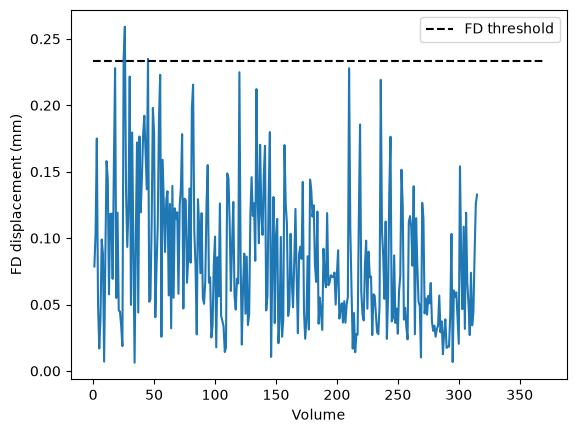

Indices of frames above threshold: [25, 26, 45]


In [10]:
#%matplotlib inline
plt.plot(list(range(1, fd.size+1)), fd)
plt.xlabel('Volume')
plt.ylabel('FD displacement (mm)')
plt.hlines(threshold, 0, 370,colors='black', linestyles='dashed', label='FD threshold')
plt.legend()
plt.show()

print(f"Indices of frames above threshold: {(np.where(fd > threshold)[0] + 1).tolist()}")

# Gaussian Smoothing

In [ ]:
fwhm = 5                       
sigma = fwhm / 2.3548

input_path = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco')
smooth_path = f'{input_path}_smoothed-{fwhm}mm'

subprocess.run(['fslmaths', input_path, '-s', str(sigma), smooth_path], check=True)

print(os.listdir(preproc_root))  

fsleyesDisplay.load(smooth_path)

['tfMRI_LANGUAGE_LR_moco.par', 'tfMRI_LANGUAGE_LR_moco.mat', 'tfMRI_LANGUAGE_LR_moco.nii.gz', 'tfMRI_LANGUAGE_LR_moco_smoothed-6mm.nii.gz', 'tfMRI_LANGUAGE_LR_moco_smoothed-5mm.nii.gz']


# Alignment between anatomical and functional data

In [ ]:
anat_dir = project_dir   # ou le dossier où se trouvent ses fichiers
whole_t1 = op.join(anat_dir, 'NOM_T1_MNI.nii.gz')                  # A REMPLIR
skull_stripped_t1 = op.join(anat_dir, 'NOM_T1_BRAIN_MNI.nii.gz')   # A REMPLIR
white_matter_segmentation = op.join(anat_dir, 'NOM_PVE_2.nii.gz')  # A REMPLIR

# --- EPI corrigé du mouvement ---
epi_source = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco')
n_vols = nib.load(epi_source + '.nii.gz').shape[3]
mid_vol = n_vols // 2                                   # 158 pour 316 volumes

ref_vol_name = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco_vol_middle')
output_path = op.join(preproc_root, 'tfMRI_LANGUAGE_LR_bbr')

# Volume de référence (1 seul volume à partir de mid_vol)
fslroi(epi_source, ref_vol_name, str(mid_vol), str(1))

# Recalage BBR avec la segmentation de substance blanche
subprocess.run(['epi_reg',
                '--epi={}'.format(ref_vol_name),
                '--t1={}'.format(whole_t1),
                '--t1brain={}'.format(skull_stripped_t1),
                '--out={}'.format(output_path),
                '--wmseg={}'.format(white_matter_segmentation)], check=True)

fsleyesDisplay.resetOverlays()
fsleyesDisplay.load(skull_stripped_t1)
fsleyesDisplay.load(output_path + '.nii.gz')

In [ ]:
func_vol = image.index_img(op.join(preproc_root, 'tfMRI_LANGUAGE_LR_moco.nii.gz'), 158)
anat_mni = skull_stripped_t1   # fichier de Mariem

display = plotting.plot_anat(anat_mni, cut_coords=(0, -20, 20), title='fMRI (contours) sur T1 MNI')
display.add_contours(func_vol, levels=[func_vol.get_fdata().mean()], colors='r')
plotting.show()